# Pandas Lab
### Working with Tables of Data

**Pandas** is the most popular Python library for **tabular data**: data in rows and columns, like a spreadsheet or a database table. You will use it to load data, clean it, analyse it and summarise it.

**What you will learn**
1. The core data structures: **Series**, **DataFrame** and **Index**
2. Related structures: **MultiIndex**, **Categorical** and the old **Panel**
3. The parts of a DataFrame and the data types pandas uses
4. Reading and writing CSV, Excel, JSON and SQL
5. Viewing, selecting, cleaning and transforming data
6. Grouping, combining and reshaping tables
7. Statistics, text (`.str`) and dates (`.dt`)
8. Plotting
9. A final project: an online store sales analysis

**How to use this lab**
1. Run the cells **from top to bottom**; later cells use tables created in earlier ones.
2. Compare your output with the **Expected output** comment in each cell. The outputs are for **pandas 2.x** (the version in Colab). In pandas 3.0 and later, text columns show the type `str` instead of `object`, and a few spacings or warnings may differ.
3. We use `print()` so you can compare outputs. Writing a table's name alone on the **last line** of a cell (for example `emp`) shows it as a nicer formatted table.
4. Lines that would crash the program are **commented out**. Uncomment one to see the error, then comment it again.

---
# Part 1: What is Pandas?

**Pandas** is a Python library for loading, cleaning, analysing and summarising **tables of data**. Its name comes from **"Panel Data"**, a term for data that records the same things over time.

- It is built on **NumPy**: every column is stored as a NumPy array, so it is fast.
- It is used everywhere in data science, finance, research and business reporting.
- It is pre-installed in Colab and Anaconda; elsewhere, install it with `pip install pandas`.
- It is always imported as `pd`:
```python
import pandas as pd
```

### Core data structures

| Component | Dimensions | What it is |
|---|---|---|
| **Series** | 1-D | A single labelled column of values with one data type |
| **DataFrame** | 2-D | A table of rows and columns; each column is a Series |
| **Index** | 1-D | The row labels (and the column labels) attached to a Series or DataFrame |

### Related structures
- **MultiIndex:** an index with more than one level, for example rows grouped by country, then by city. It is what `groupby` on several columns produces (Parts 11 and 12).
- **Categorical:** a memory-efficient type for columns with a few repeating values, such as a segment column. It is what `pd.cut` produces (Parts 10 and 12).
- **Panel (3-D):** the structure the name *Panel Data* comes from. It was **removed in pandas 0.25 (2019)**; DataFrames with a MultiIndex replace it.

### Tool groups: what you do with these structures

| Group | Main functions | Part |
|---|---|---|
| Input / Output | `read_csv`, `read_excel`, `read_json`, `read_sql`, `to_csv`, `to_excel` | 6 |
| Viewing and inspecting | `head`, `tail`, `sample`, `shape`, `info`, `describe`, `dtypes` | 7 |
| Selecting | `[]`, dot operator, `loc`, `iloc`, boolean filtering, `query` | 8 |
| Cleaning | `isnull`, `fillna`, `dropna`, `drop`, `duplicated`, `drop_duplicates`, `rename`, `astype`, `replace` | 9 |
| Transforming | `apply`, `map`, `pd.cut`, `sort_values`, `value_counts`, `unique`, `nunique` | 10 |
| Grouping and aggregating | `groupby`, `agg`, `pivot_table`, `crosstab` | 11 |
| Combining | `concat`, `merge`, `join` | 13 |
| Reshaping | `melt`, `pivot`, `stack`, `unstack` | 14 |
| Statistics | `mean`, `median`, `mode`, `std`, `corr`, `quantile` | 15 |
| Text accessor | `.str` (e.g. `.str.replace`, `.str.lower`) | 16 |
| Date accessor | `.dt` (e.g. `.dt.month`, `.dt.day_name()`) | 17 |
| Plotting | `.plot()`, `.hist()` (built on Matplotlib) | 18 |

**Diagram: Anatomy of a DataFrame**

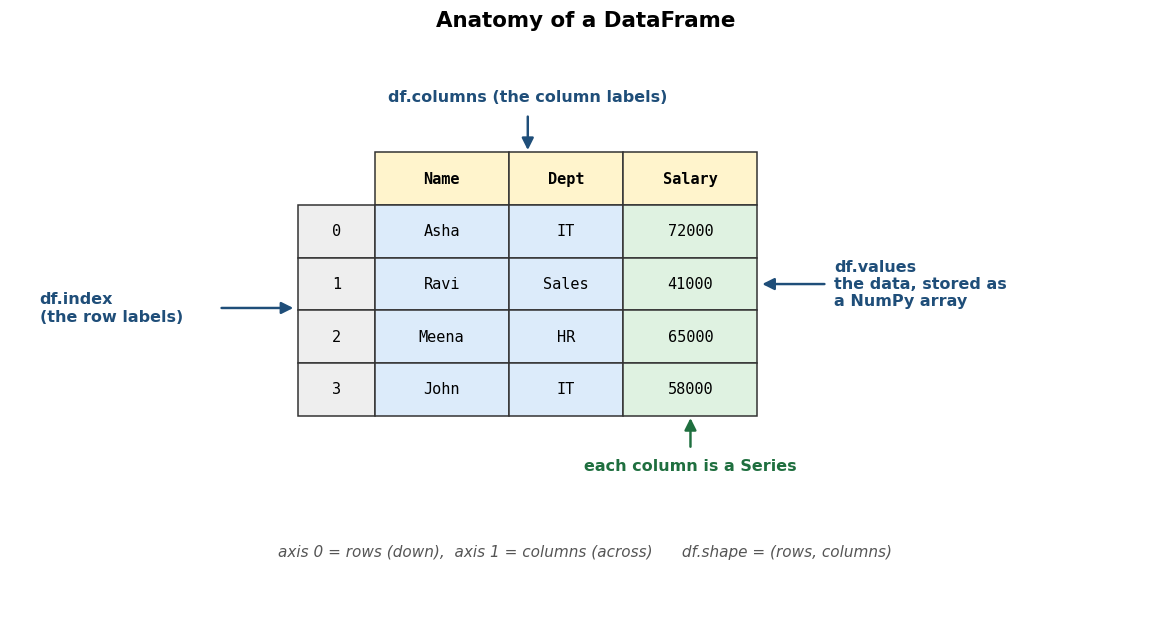

In [ ]:
# Example 1: Importing pandas (and NumPy, which pandas is built on)
import pandas as pd
import numpy as np
print(pd.__version__)
# Expected output: a version number such as 2.2.2

In [ ]:
# Example 2: Our first DataFrame - this 'emp' table is used in most of the lab (do not change it)
data = {
    'Name': ['Asha', 'Ravi', 'Meena', 'John', 'Sara', 'Kiran', 'Priya', 'Arjun', 'Neha'],
    'Dept': ['IT', 'Sales', 'HR', 'IT', 'Sales', 'IT', 'HR', 'Sales', 'IT'],
    'City': ['Pune', 'Mumbai', 'Pune', 'Delhi', 'Delhi', 'Mumbai', 'Mumbai', 'Pune', 'Pune'],
    'Experience': [5, 2, 8, 3, 6, 10, 1, 4, 6],
    'Salary': [72000, 41000, 65000, 58000, 55000, 95000, 38000, 48000, 68000],
}
emp = pd.DataFrame(data)
print(emp)
# Expected output:
#     Name   Dept    City  Experience  Salary
# 0   Asha     IT    Pune           5   72000
# 1   Ravi  Sales  Mumbai           2   41000
# 2  Meena     HR    Pune           8   65000
# 3   John     IT   Delhi           3   58000
# 4   Sara  Sales   Delhi           6   55000
# 5  Kiran     IT  Mumbai          10   95000
# 6  Priya     HR  Mumbai           1   38000
# 7  Arjun  Sales    Pune           4   48000
# 8   Neha     IT    Pune           6   68000

In [ ]:
# Example 3: The three core structures in one table
print(type(emp))              # the whole table
print(type(emp['Salary']))    # one column
print(type(emp.index))        # the row labels
# Expected output:
# <class 'pandas.core.frame.DataFrame'>
# <class 'pandas.core.series.Series'>
# <class 'pandas.core.indexes.range.RangeIndex'>

---
# Part 2: Series - One Labelled Column

A **Series** is a 1-D array of values **with labels**.

| Part | Meaning | How to see it |
|---|---|---|
| values | the data (a NumPy array) | `s.values` |
| index | one label for each value | `s.index` |
| dtype | one data type for all the values | `s.dtype` |
| name | an optional name (it becomes the column name in a DataFrame) | `s.name` |

**Creating a Series:** `pd.Series(list)`, `pd.Series(list, index=labels)` or `pd.Series(dictionary)`.

**Selecting:** by label with `s['Math']` (or `s.loc['Math']`), by position with `s.iloc[0]`.

Like NumPy arrays, a Series supports **element-wise maths** and **boolean filtering**, without loops.

**Diagram: Parts of a Series**

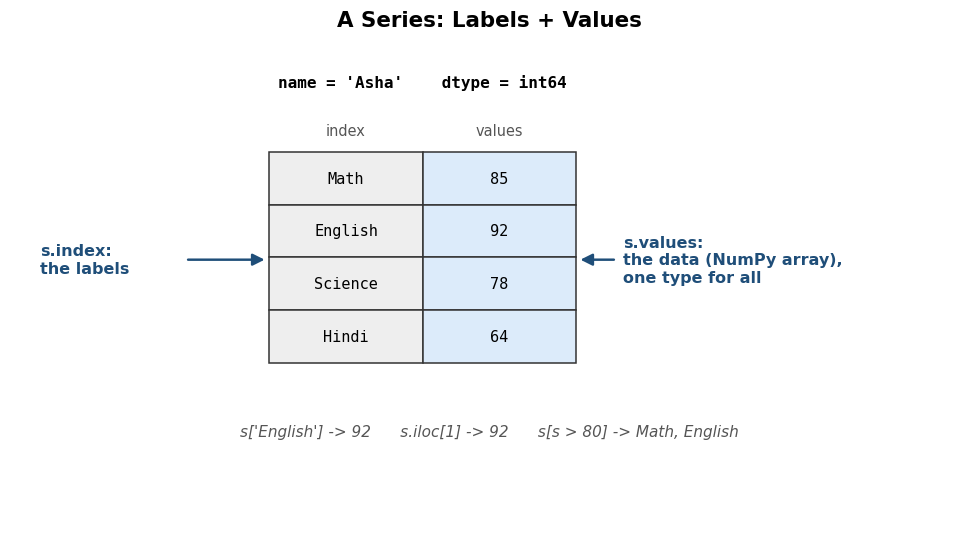

In [ ]:
# Example 1: A Series from a list - pandas adds the labels 0, 1, 2
marks = pd.Series([85, 92, 78])
print(marks)
# Expected output:
# 0    85
# 1    92
# 2    78
# dtype: int64

In [ ]:
# Example 2: Your own labels and a name
marks = pd.Series([85, 92, 78, 64], index=['Math', 'English', 'Science', 'Hindi'], name='Asha')
print(marks)
# Expected output:
# Math       85
# English    92
# Science    78
# Hindi      64
# Name: Asha, dtype: int64

In [ ]:
# Example 3: A Series from a dictionary - the keys become the labels
prices = pd.Series({'Apple': 120, 'Banana': 40, 'Mango': 150})     # price per kg
print(prices)
print(prices.index)
print(prices.values)
print(prices.dtype, prices.size)
# Expected output:
# Apple     120
# Banana     40
# Mango     150
# dtype: int64
# Index(['Apple', 'Banana', 'Mango'], dtype='object')
# [120  40 150]
# int64 3

In [ ]:
# Example 4: Selecting by label and by position
print(marks['English'])          # by label
print(marks.iloc[0])             # by position
print(marks[['Math', 'Hindi']])  # several labels give a smaller Series
# Expected output:
# 92
# 85
# Math     85
# Hindi    64
# Name: Asha, dtype: int64

In [ ]:
# Example 5: Maths and filtering work on the whole Series
print(marks + 5)
print(marks[marks >= 80])
print(marks.mean(), marks.max(), marks.idxmax())     # idxmax() gives the LABEL of the largest value
# Expected output:
# Math       90
# English    97
# Science    83
# Hindi      69
# Name: Asha, dtype: int64
# Math       85
# English    92
# Name: Asha, dtype: int64
# 79.75 92 English

---
# Part 3: DataFrame - A Table

A **DataFrame** is a 2-D table. Every column is a **Series**, and all the columns share the same **index** (row labels).

**Ways to create one:** from a dictionary of lists (one list per column, as in Part 1), from a list of dictionaries (one dictionary per row), or from a 2-D NumPy array.

### Parts of a DataFrame

| Part | How to see it | Example from `emp` |
|---|---|---|
| Index (row labels) | `df.index` | `0, 1, 2 ...` (or labels such as `Math, English ...`) |
| Columns (column labels) | `df.columns` | `Name, Dept, City, Experience, Salary` |
| Values (the data) | `df.values` | the underlying NumPy array |
| Data types | `df.dtypes` | `int64`, `float64`, `object`, `datetime64` |
| Axes | `df.axes` | axis 0 = rows, axis 1 = columns |
| Shape | `df.shape` | `(9, 5)`: 9 rows, 5 columns |
| Size and dimensions | `df.size`, `df.ndim` | `45`, `2` |

In [ ]:
# Example 1: From a list of dictionaries - one dictionary per row
rows = [{'Subject': 'Math', 'Marks': 85, 'Grade': 'A'},
        {'Subject': 'English', 'Marks': 92, 'Grade': 'A+'},
        {'Subject': 'Science', 'Marks': 78, 'Grade': 'B'}]
report = pd.DataFrame(rows)
print(report)
# Expected output:
#    Subject  Marks Grade
# 0     Math     85     A
# 1  English     92    A+
# 2  Science     78     B

In [ ]:
# Example 2: From a NumPy array, with column names and row labels
arr = np.array([[25, 30], [28, 35], [22, 27]])
temps = pd.DataFrame(arr, columns=['Min', 'Max'], index=['Mon', 'Tue', 'Wed'])
print(temps)
# Expected output:
#      Min  Max
# Mon   25   30
# Tue   28   35
# Wed   22   27

In [ ]:
# Example 3: The parts of a DataFrame
print(emp.index)
print(emp.columns)
print(emp.shape, emp.size, emp.ndim)
print(len(emp.axes), emp.axes[1].tolist())     # axes[0] = row labels, axes[1] = column labels
print(type(emp.values))
print(emp[['Experience', 'Salary']].values[:3])
print(emp.dtypes)
# Expected output:
# RangeIndex(start=0, stop=9, step=1)
# Index(['Name', 'Dept', 'City', 'Experience', 'Salary'], dtype='object')
# (9, 5) 45 2
# 2 ['Name', 'Dept', 'City', 'Experience', 'Salary']
# <class 'numpy.ndarray'>
# [[    5 72000]
#  [    2 41000]
#  [    8 65000]]
# Name          object
# Dept          object
# City          object
# Experience     int64
# Salary         int64
# dtype: object

In [ ]:
# Example 4: Each column is a Series
col = emp['Salary']
print(type(col), col.name)
print(col.head(3))
# Expected output:
# <class 'pandas.core.series.Series'> Salary
# 0    72000
# 1    41000
# 2    65000
# Name: Salary, dtype: int64

---
# Part 4: The Index

The **index** holds the row labels. The column labels are also an Index (`df.columns`).

- By default the index is a **RangeIndex**: `0, 1, 2, ...`
- `df.set_index('column')` turns a column into the index; `df.reset_index()` turns the index back into a column.
- Labels make selection readable: `people.loc['Kiran']` instead of remembering that Kiran is row 5.
- **Alignment:** when two Series are combined, pandas matches values by **label**, not by position. A label found on only one side gives `NaN` (missing).

Most methods (`set_index`, `reset_index`, `sort_values` ...) return a **new** DataFrame; the original stays the same unless you assign the result.

**Diagram: Index alignment**

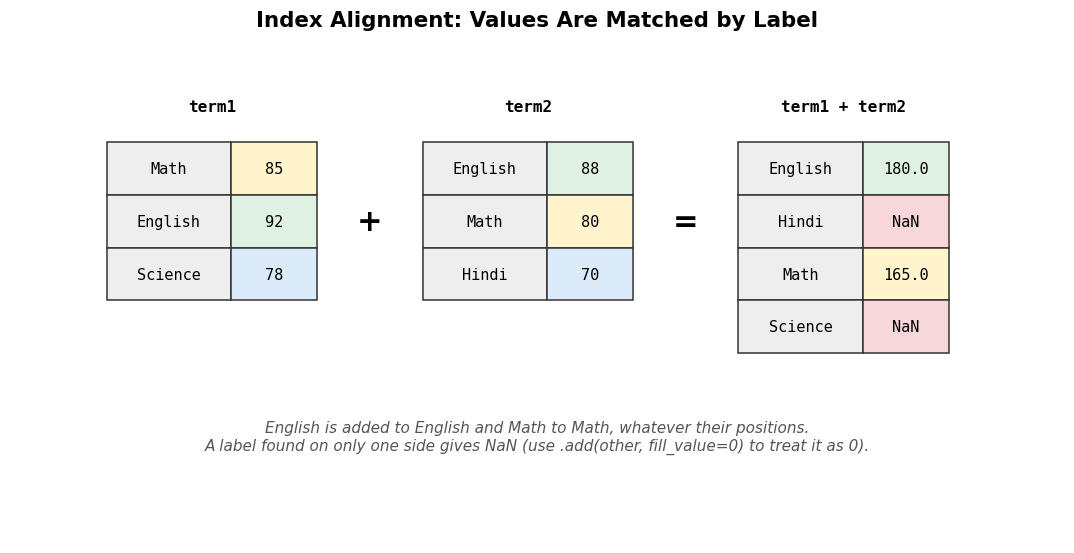

In [ ]:
# Example 1: Using the Name column as the index
people = emp.set_index('Name')
print(people.head(3))
print(people.index.name, list(people.index[:3]))
# Expected output:
#         Dept    City  Experience  Salary
# Name
# Asha      IT    Pune           5   72000
# Ravi   Sales  Mumbai           2   41000
# Meena     HR    Pune           8   65000
# Name ['Asha', 'Ravi', 'Meena']

In [ ]:
# Example 2: Selecting a row by its label
print(people.loc['Kiran'])
# Expected output:
# Dept              IT
# City          Mumbai
# Experience        10
# Salary         95000
# Name: Kiran, dtype: object

In [ ]:
# Example 3: reset_index() turns the index back into a column
back = people.reset_index()
print(back.columns.tolist())
print(back.index)
# Expected output:
# ['Name', 'Dept', 'City', 'Experience', 'Salary']
# RangeIndex(start=0, stop=9, step=1)

In [ ]:
# Example 4: Alignment - values are matched by LABEL, not by position
term1 = pd.Series([85, 92, 78], index=['Math', 'English', 'Science'])
term2 = pd.Series([88, 80, 70], index=['English', 'Math', 'Hindi'])
print(term1 + term2)
print(term1.add(term2, fill_value=0))       # treat a missing label as 0
# Expected output:
# English    180.0
# Hindi        NaN
# Math       165.0
# Science      NaN
# dtype: float64
# English    180.0
# Hindi       70.0
# Math       165.0
# Science     78.0
# dtype: float64

---
# Part 5: Data Types Pandas Uses

| dtype | Holds | Example |
|---|---|---|
| `int64` | whole numbers | `25`, `72000` |
| `float64` | decimals (and whole numbers with missing values) | `3.5`, `NaN` |
| `object` | text, or mixed types | `'Pune'` |
| `bool` | `True` / `False` | `True` |
| `datetime64` | dates and times (from `pd.to_datetime`) | `2026-01-05` |
| `timedelta64` | differences between dates | `86 days` |
| `category` | a few repeating labels (from `astype('category')` or `pd.cut`) | `'Low'`, `'High'` |

- Check the types with `df.dtypes`; convert with `astype()`, `pd.to_datetime()` or `pd.to_numeric()`.
- **Numbers stored as text** (`'5'`, `'12'`) cannot be added up correctly; convert them first.
- A column of whole numbers with a missing value becomes `float64`, because `NaN` is a float.
- In pandas 3.0 and later, text columns use the new `str` type instead of `object`.

In [ ]:
# Example 1: One column of each common type
stock = pd.DataFrame({
    'Product': ['Pen', 'Book', 'Bag'],
    'Qty': [10, 2, 1],
    'Price': [10.5, 250.0, 799.0],
    'InStock': [True, False, True],
    'Added': pd.to_datetime(['2026-01-05', '2026-02-10', '2026-03-15']),
})
print(stock.dtypes)
# Expected output:
# Product            object
# Qty                 int64
# Price             float64
# InStock              bool
# Added      datetime64[ns]
# dtype: object

In [ ]:
# Example 2: timedelta64 - the difference between two dates
deadline = pd.to_datetime('2026-04-01')
stock['DaysListed'] = deadline - stock['Added']
print(stock['DaysListed'])
print(stock['DaysListed'].dt.days)        # just the number of days
# Expected output:
# 0   86 days
# 1   50 days
# 2   17 days
# Name: DaysListed, dtype: timedelta64[ns]
# 0    86
# 1    50
# 2    17
# Name: DaysListed, dtype: int64

In [ ]:
# Example 3: category - a few repeating labels use much less memory
sizes = pd.Series(['Small', 'Large', 'Medium', 'Small', 'Small', 'Large'] * 1000)   # 6000 values
as_cat = sizes.astype('category')
print(sizes.dtype, '->', as_cat.dtype)
print('object memory  :', sizes.memory_usage(deep=True), 'bytes')
print('category memory:', as_cat.memory_usage(deep=True), 'bytes')
print(as_cat.cat.categories)
# Expected output (the memory numbers depend on your system):
# object -> category
# object memory  : about 370000 bytes
# category memory: about 6400 bytes
# Index(['Large', 'Medium', 'Small'], dtype='object')

In [ ]:
# Example 4: Fixing types - text to int, yes/no to bool
raw = pd.DataFrame({'Qty': ['5', '12', '7'], 'Paid': ['yes', 'no', 'yes']})
print(raw.dtypes)
raw['Qty'] = raw['Qty'].astype(int)
raw['Paid'] = raw['Paid'] == 'yes'
print(raw.dtypes)
print(raw['Qty'].sum(), raw['Paid'].sum())     # True counts as 1
# Expected output:
# Qty     object
# Paid    object
# dtype: object
# Qty     int64
# Paid     bool
# dtype: object
# 24 2

---
# Part 6: Input and Output (Reading and Writing Files)

| Read | Write | Format |
|---|---|---|
| `pd.read_csv(file)` | `df.to_csv(file, index=False)` | CSV text files (the most common) |
| `pd.read_excel(file, sheet_name=...)` | `df.to_excel(file, index=False)` | Excel `.xlsx` (needs the `openpyxl` package, installed in Colab) |
| `pd.read_json(file)` | `df.to_json(file, orient='records')` | JSON, used by web APIs |
| `pd.read_sql(query, connection)` | `df.to_sql(table, connection)` | SQL databases |

Useful options for `read_csv`: `usecols=` (only some columns), `nrows=` (only the first rows), `index_col=` (use a column as the index), `parse_dates=` (read date columns as dates), `sep=` (a different separator).

**`index=False`** when writing stops pandas from saving the row numbers as an extra column.

In [ ]:
# Example 1: CSV - write, look inside, read back
emp.to_csv('employees.csv', index=False)
with open('employees.csv', 'r', encoding='utf-8') as f:
    for i in range(3):
        print(f.readline(), end='')
loaded = pd.read_csv('employees.csv')
print(loaded.shape)
print(loaded.equals(emp))          # exactly the same table?
# Expected output:
# Name,Dept,City,Experience,Salary
# Asha,IT,Pune,5,72000
# Ravi,Sales,Mumbai,2,41000
# (9, 5)
# True

In [ ]:
# Example 2: Reading only some columns and rows
part = pd.read_csv('employees.csv', usecols=['Name', 'Salary'], nrows=3)
print(part)
# Expected output:
#     Name  Salary
# 0   Asha   72000
# 1   Ravi   41000
# 2  Meena   65000

In [ ]:
# Example 3: Excel
emp.to_excel('employees.xlsx', index=False, sheet_name='Staff')
from_excel = pd.read_excel('employees.xlsx', sheet_name='Staff')
print(from_excel.shape, from_excel.columns.tolist())
# Expected output: (9, 5) ['Name', 'Dept', 'City', 'Experience', 'Salary']

In [ ]:
# Example 4: JSON
emp.head(2).to_json('employees.json', orient='records')
with open('employees.json', 'r', encoding='utf-8') as f:
    print(f.read())
print(pd.read_json('employees.json').shape)
# Expected output:
# [{"Name":"Asha","Dept":"IT","City":"Pune","Experience":5,"Salary":72000},{"Name":"Ravi","Dept":"Sales","City":"Mumbai","Experience":2,"Salary":41000}]
# (2, 5)

In [ ]:
# Example 5: SQL - Python's built-in sqlite3 database
import sqlite3
conn = sqlite3.connect(':memory:')              # a temporary database in memory
emp.to_sql('employees', conn, index=False)      # save the table into the database
query = "SELECT Name, Salary FROM employees WHERE Dept = 'IT' ORDER BY Salary DESC"
it_staff = pd.read_sql(query, conn)
print(it_staff)
conn.close()
# Expected output:
#     Name  Salary
# 0  Kiran   95000
# 1   Asha   72000
# 2   Neha   68000
# 3   John   58000

---
# Part 7: Viewing and Inspecting Data

The first thing to do with any new data is to **look at it**.

| Code | Shows |
|---|---|
| `df.head(n)` / `df.tail(n)` | the first / last n rows (default 5) |
| `df.sample(n, random_state=1)` | n random rows (repeatable with `random_state`) |
| `df.shape` | (rows, columns) |
| `df.info()` | columns, non-missing counts, types and memory |
| `df.describe()` | count, mean, std, min, quartiles and max of the number columns |
| `df.dtypes` | the type of each column |
| `df.columns` | the column names |
| `df.nunique()` | the number of different values in each column |

In [ ]:
# Example 1: The first and last rows
print(emp.head(3))
print(emp.tail(2))
# Expected output:
#     Name   Dept    City  Experience  Salary
# 0   Asha     IT    Pune           5   72000
# 1   Ravi  Sales  Mumbai           2   41000
# 2  Meena     HR    Pune           8   65000
#     Name   Dept  City  Experience  Salary
# 7  Arjun  Sales  Pune           4   48000
# 8   Neha     IT  Pune           6   68000

In [ ]:
# Example 2: A random sample of rows
print(emp.sample(3, random_state=1))
# Expected output: 3 random rows - the SAME 3 every time, because of random_state

In [ ]:
# Example 3: info() - a quick summary of the whole table
emp.info()
# Expected output:
# <class 'pandas.core.frame.DataFrame'>
# RangeIndex: 9 entries, 0 to 8
# Data columns (total 5 columns):
#  #   Column      Non-Null Count  Dtype
# ---  ------      --------------  -----
#  0   Name        9 non-null      object
#  1   Dept        9 non-null      object
#  2   City        9 non-null      object
#  3   Experience  9 non-null      int64
#  4   Salary      9 non-null      int64
# dtypes: int64(2), object(3)
# memory usage: ... bytes   (the number depends on your system)

In [ ]:
# Example 4: describe() - statistics of the number columns (rounded to 2 decimals)
print(emp[['Experience', 'Salary']].describe().round(2))
# Expected output:
#        Experience    Salary
# count        9.00      9.00
# mean         5.00  60000.00
# std          2.87  17592.61
# min          1.00  38000.00
# 25%          3.00  48000.00
# 50%          5.00  58000.00
# 75%          6.00  68000.00
# max         10.00  95000.00

In [ ]:
# Example 5: Column names and the number of different values per column
print(emp.columns.tolist())
print(emp.nunique())
# Expected output:
# ['Name', 'Dept', 'City', 'Experience', 'Salary']
# Name          9
# Dept          3
# City          3
# Experience    8
# Salary        9
# dtype: int64

---
# Part 8: Selecting Data

| Code | Selects | Result |
|---|---|---|
| `df['Salary']` | one column | Series |
| `df[['Name', 'Salary']]` | several columns (note the double brackets) | DataFrame |
| `df.Salary` | one column, with the **dot operator** | Series |
| `df.loc[row_label, col_label]` | by **labels**; slices **include** the end | value, Series or DataFrame |
| `df.iloc[row_pos, col_pos]` | by **positions**; slices **exclude** the end | value, Series or DataFrame |
| `df[df['Salary'] > 60000]` | rows where a condition is True | DataFrame |
| `df.query('Salary > 60000')` | the same, written as text | DataFrame |

- The dot operator works only for simple names: not for names with spaces, or names that clash with methods (`count`, `size` ...).
- Combine conditions with `&` (and), `|` (or), `~` (not), with brackets around each condition.
- `isin([...])` checks membership in a list; `between(a, b)` checks a range (both ends included).
- To **change** selected values, use `df.loc[condition, 'column'] = value`.

**Diagram: loc vs iloc**

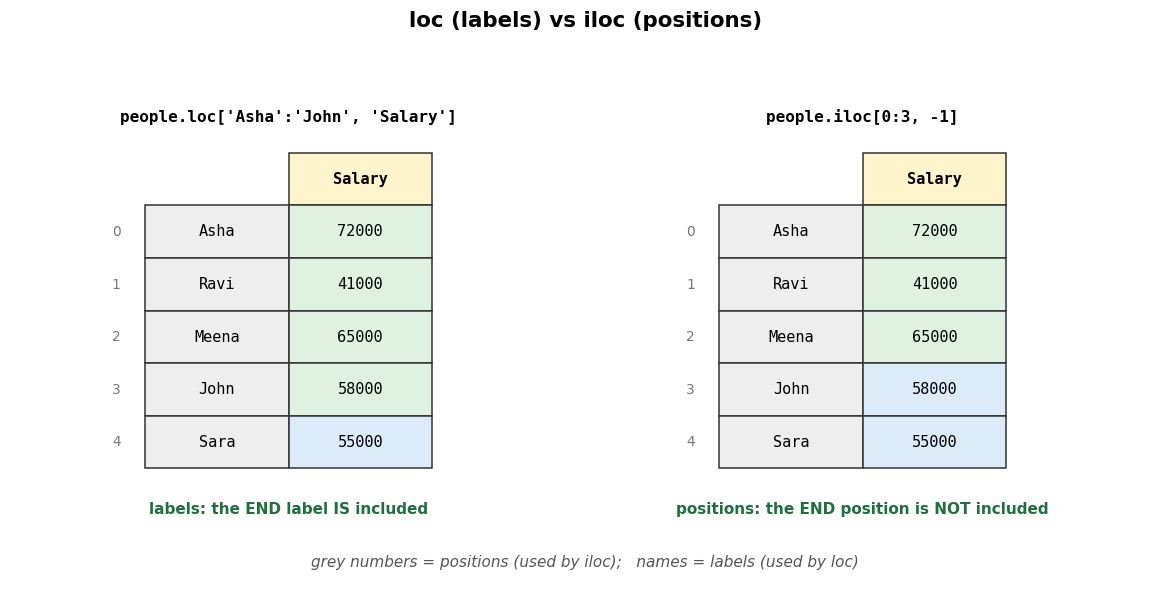

In [ ]:
# Example 1: One column (Series) vs several columns (DataFrame)
print(emp['Name'].head(3))
print(emp[['Name', 'Salary']].head(3))
# Expected output:
# 0     Asha
# 1     Ravi
# 2    Meena
# Name: Name, dtype: object
#     Name  Salary
# 0   Asha   72000
# 1   Ravi   41000
# 2  Meena   65000

In [ ]:
# Example 2: The dot operator - a shortcut for simple column names
print(emp.Salary.max())
print(emp.Dept.unique())
# emp.Monthly Salary    # a name with a space cannot be used with the dot operator
# emp.size is the number of cells (45), not a column: a column named 'size' would need emp['size']
# Expected output:
# 95000
# ['IT' 'Sales' 'HR']

In [ ]:
# Example 3: loc - select by LABELS (the end of a slice is included)
print(emp.loc[2])                         # the row with label 2
print(emp.loc[2, 'Name'])
print(emp.loc[0:2, ['Name', 'Dept']])     # labels 0, 1 AND 2
# Expected output:
# Name          Meena
# Dept             HR
# City           Pune
# Experience        8
# Salary        65000
# Name: 2, dtype: object
# Meena
#     Name   Dept
# 0   Asha     IT
# 1   Ravi  Sales
# 2  Meena     HR

In [ ]:
# Example 4: iloc - select by POSITIONS (the end of a slice is excluded, like lists)
print(emp.iloc[0, 0])
print(emp.iloc[0:2, 0:2])                 # positions 0 and 1 only
print(emp.iloc[-1]['Name'])               # the last row
# Expected output:
# Asha
#    Name   Dept
# 0  Asha     IT
# 1  Ravi  Sales
# Neha

In [ ]:
# Example 5: loc vs iloc with name labels (people = emp.set_index('Name') from Part 4)
print(people.loc['Asha':'John', 'Salary'])    # labels: John IS included
print(people.iloc[0:3, -1])                   # positions: 3 is NOT included
# Expected output:
# Name
# Asha     72000
# Ravi     41000
# Meena    65000
# John     58000
# Name: Salary, dtype: int64
# Name
# Asha     72000
# Ravi     41000
# Meena    65000
# Name: Salary, dtype: int64

In [ ]:
# Example 6: Boolean filtering
print(emp[emp['Salary'] > 65000])
print(emp[(emp['Dept'] == 'IT') & (emp['City'] == 'Pune')])
print(emp[emp['City'].isin(['Delhi', 'Mumbai'])]['Name'].tolist())
print(emp[emp['Experience'].between(3, 6)]['Name'].tolist())
# Expected output:
#     Name Dept    City  Experience  Salary
# 0   Asha   IT    Pune           5   72000
# 5  Kiran   IT  Mumbai          10   95000
# 8   Neha   IT    Pune           6   68000
#    Name Dept  City  Experience  Salary
# 0  Asha   IT  Pune           5   72000
# 8  Neha   IT  Pune           6   68000
# ['Ravi', 'John', 'Sara', 'Kiran', 'Priya']
# ['Asha', 'John', 'Sara', 'Arjun', 'Neha']

In [ ]:
# Example 7: query() - the same filters written as text
print(emp.query('Salary > 60000 and City == "Pune"')[['Name', 'Salary']])
limit = 50000
print(emp.query('Salary < @limit')['Name'].tolist())     # @ uses a Python variable
# Expected output:
#     Name  Salary
# 0   Asha   72000
# 2  Meena   65000
# 8   Neha   68000
# ['Ravi', 'Priya', 'Arjun']

In [ ]:
# Example 8: Changing selected values with loc (on a copy, so emp stays unchanged)
emp2 = emp.copy()
emp2.loc[emp2['Dept'] == 'Sales', 'Salary'] += 5000
print(emp2.loc[emp2['Dept'] == 'Sales', ['Name', 'Salary']])
# emp2[emp2['Dept'] == 'Sales']['Salary'] = 0   # WRONG (chained): may change a temporary copy only
# Expected output:
#     Name  Salary
# 1   Ravi   46000
# 4   Sara   60000
# 7  Arjun   53000

---
# Part 9: Cleaning Data

Real data is messy: missing values, duplicates, inconsistent text, numbers stored as text. Cleaning usually takes most of the time in a data project.

| Problem | Find it | Fix it |
|---|---|---|
| Missing values (`NaN` / `None`) | `df.isnull()`, `df.isnull().sum()` | `fillna(value)`, `dropna()` |
| Duplicate rows | `df.duplicated()` | `drop_duplicates()` |
| Unwanted rows / columns | | `drop(index=...)`, `drop(columns=...)` |
| Bad column names | `df.columns` | `rename(columns={'old': 'new'})` |
| Wrong values | `value_counts()` | `replace(old, new)` |
| Wrong types | `df.dtypes` | `astype(type)`, `pd.to_numeric(..., errors='coerce')` |

`isna()` is the same as `isnull()`. These methods return a **new** object: write `df = df.dropna()`, not just `df.dropna()`.

**Diagram: A typical cleaning pipeline**

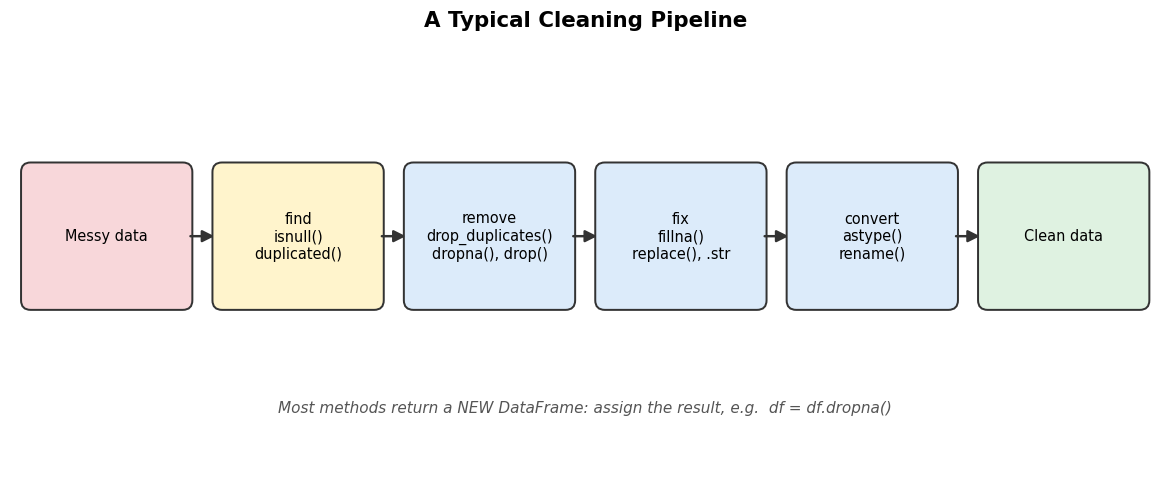

In [ ]:
# Setup: a messy table (missing values, a duplicate row, mixed-case text, a number stored as text)
messy = pd.DataFrame({
    'Name': ['Asha', 'Ravi', 'Meena', 'Ravi', 'John', None],
    'Age': [25, None, 31, None, 28, 40],
    'City': ['Pune', 'mumbai', 'Pune', 'mumbai', None, 'Delhi'],
    'Salary': ['50000', '42000', '61000', '42000', 'unknown', '55000'],
})
print(messy)
# Expected output:
#     Name   Age    City   Salary
# 0   Asha  25.0    Pune    50000
# 1   Ravi   NaN  mumbai    42000
# 2  Meena  31.0    Pune    61000
# 3   Ravi   NaN  mumbai    42000
# 4   John  28.0    None  unknown
# 5   None  40.0   Delhi    55000

In [ ]:
# Example 1: Finding missing values
print(messy.isnull().sum())           # missing values per column
print(messy.isnull().sum().sum())     # in the whole table
# Expected output:
# Name      1
# Age       2
# City      1
# Salary    0
# dtype: int64
# 4

In [ ]:
# Example 2: Finding and removing duplicate rows
print(messy.duplicated())
print('Duplicates:', messy.duplicated().sum())
clean = messy.drop_duplicates().copy()
print(clean.shape)
# Expected output:
# 0    False
# 1    False
# 2    False
# 3     True
# 4    False
# 5    False
# dtype: bool
# Duplicates: 1
# (5, 4)

In [ ]:
# Example 3: Filling and dropping missing values
clean['Age'] = clean['Age'].fillna(clean['Age'].mean())     # fill with the average age (31.0)
clean['City'] = clean['City'].fillna('Unknown')
clean = clean.dropna(subset=['Name'])                         # a row without a name is useless
print(clean)
# Expected output:
#     Name   Age     City   Salary
# 0   Asha  25.0     Pune    50000
# 1   Ravi  31.0   mumbai    42000
# 2  Meena  31.0     Pune    61000
# 4   John  28.0  Unknown  unknown

In [ ]:
# Example 4: replace, astype, to_numeric and rename
clean['City'] = clean['City'].replace({'mumbai': 'Mumbai'})
clean['Age'] = clean['Age'].astype(int)
clean['Salary'] = pd.to_numeric(clean['Salary'], errors='coerce')   # 'unknown' becomes NaN
clean = clean.rename(columns={'Salary': 'MonthlySalary'})
print(clean)
print(clean.dtypes)
print(clean['MonthlySalary'].mean())       # NaN is skipped automatically
# Expected output:
#     Name  Age     City  MonthlySalary
# 0   Asha   25     Pune        50000.0
# 1   Ravi   31   Mumbai        42000.0
# 2  Meena   31     Pune        61000.0
# 4   John   28  Unknown            NaN
# Name              object
# Age                int64
# City              object
# MonthlySalary    float64
# dtype: object
# 51000.0

In [ ]:
# Example 5: Dropping columns and rows
print(clean.drop(columns=['City']).columns.tolist())
print(clean.drop(index=[0, 1]).index.tolist())
# Expected output:
# ['Name', 'Age', 'MonthlySalary']
# [2, 4]

---
# Part 10: Transforming Data

| Tool | Does | Example |
|---|---|---|
| arithmetic on columns | creates a new column | `df['Bonus'] = df['Salary'] * 0.10` |
| `apply(function)` | runs a function on every value (or every row, with `axis=1`) | `df['Experience'].apply(level)` |
| `map(dictionary)` | replaces each value using a dictionary | `df['Dept'].map(names)` |
| `pd.cut(column, bins, labels)` | puts numbers into ranges; gives a **Categorical** column | Low / Medium / High |
| `sort_values(column)` | sorts the rows | `ascending=False` for largest first |
| `value_counts()` | counts each value | staff per city |
| `unique()` / `nunique()` | the distinct values / how many there are | |

Prefer **vectorised** column arithmetic when you can; use `apply` for logic that needs `if`/`elif`.

In [ ]:
# Example 1: New columns from arithmetic (on a copy, so emp stays unchanged)
pay = emp.copy()
pay['Bonus'] = pay['Salary'] * 0.10
pay['Total'] = pay['Salary'] + pay['Bonus']
print(pay[['Name', 'Salary', 'Bonus', 'Total']].head(3))
# Expected output:
#     Name  Salary   Bonus    Total
# 0   Asha   72000  7200.0  79200.0
# 1   Ravi   41000  4100.0  45100.0
# 2  Meena   65000  6500.0  71500.0

In [ ]:
# Example 2: apply - run your own function on every value, or on every row
def level(years):
    if years >= 8:
        return 'Senior'
    elif years >= 4:
        return 'Mid'
    return 'Junior'

emp_t = emp.copy()
emp_t['Level'] = emp_t['Experience'].apply(level)
print(emp_t[['Name', 'Experience', 'Level']].head(4))
emp_t['Summary'] = emp_t.apply(lambda row: f"{row['Name']} ({row['Dept']})", axis=1)   # axis=1: one row at a time
print(emp_t['Summary'].head(2).tolist())
# Expected output:
#     Name  Experience   Level
# 0   Asha           5     Mid
# 1   Ravi           2  Junior
# 2  Meena           8  Senior
# 3   John           3  Junior
# ['Asha (IT)', 'Ravi (Sales)']

In [ ]:
# Example 3: map - translate values with a dictionary
dept_names = {'IT': 'Information Technology', 'HR': 'Human Resources', 'Sales': 'Sales & Marketing'}
emp_t['DeptName'] = emp_t['Dept'].map(dept_names)
print(emp_t[['Dept', 'DeptName']].drop_duplicates())
# Expected output:
#     Dept                DeptName
# 0     IT  Information Technology
# 1  Sales       Sales & Marketing
# 2     HR         Human Resources

In [ ]:
# Example 4: pd.cut - salary segments (the result is a Categorical column)
bins = [0, 45000, 70000, 100000]           # (0, 45000], (45000, 70000], (70000, 100000]
labels = ['Low', 'Medium', 'High']
emp_t['Segment'] = pd.cut(emp_t['Salary'], bins=bins, labels=labels)
print(emp_t[['Name', 'Salary', 'Segment']].head(4))
print(emp_t['Segment'].dtype)
print(emp_t['Segment'].value_counts(sort=False))     # sort=False keeps the order Low, Medium, High
# Expected output:
#     Name  Salary Segment
# 0   Asha   72000    High
# 1   Ravi   41000     Low
# 2  Meena   65000  Medium
# 3   John   58000  Medium
# category
# Segment
# Low       2
# Medium    5
# High      2
# Name: count, dtype: int64

In [ ]:
# Example 5: sort_values - by one column, or by several
print(emp.sort_values('Salary', ascending=False).head(3)[['Name', 'Salary']])
by_dept = emp.sort_values(['Dept', 'Experience'], ascending=[True, False])
print(by_dept[['Name', 'Dept', 'Experience']].head(4))
# Expected output:
#     Name  Salary
# 5  Kiran   95000
# 0   Asha   72000
# 8   Neha   68000
#     Name Dept  Experience
# 2  Meena   HR           8
# 6  Priya   HR           1
# 5  Kiran   IT          10
# 8   Neha   IT           6

In [ ]:
# Example 6: value_counts, unique and nunique
print(emp['City'].value_counts())
print(emp['Dept'].unique())
print(emp['Dept'].nunique())
print(emp['City'].value_counts(normalize=True).round(2))     # shares instead of counts
# Expected output:
# City
# Pune      4
# Mumbai    3
# Delhi     2
# Name: count, dtype: int64
# ['IT' 'Sales' 'HR']
# 3
# City
# Pune      0.44
# Mumbai    0.33
# Delhi     0.22
# Name: proportion, dtype: float64

---
# Part 11: Grouping and Aggregating

`groupby` follows three steps, called **split-apply-combine**:
1. **Split** the rows into groups (for example, one group per department)
2. **Apply** a calculation to each group (mean, sum, count ...)
3. **Combine** the results into a new table, with one row per group

| Tool | Use |
|---|---|
| `df.groupby('Dept')['Salary'].mean()` | one statistic for each group |
| `.agg(['count', 'mean', 'max'])` | several statistics at once |
| `.agg(new_name=('column', 'function'))` | named aggregation: you choose the result column names |
| `df.groupby(['Dept', 'City'])` | groups by two columns; the result has a **MultiIndex** |
| `df.pivot_table(values, index, columns, aggfunc)` | a spreadsheet-style summary table |
| `pd.crosstab(rows, columns)` | counts of every combination of two columns |

The group labels become the **index** of the result; use `reset_index()` to turn them back into a column.

**Diagram: Split - apply - combine**

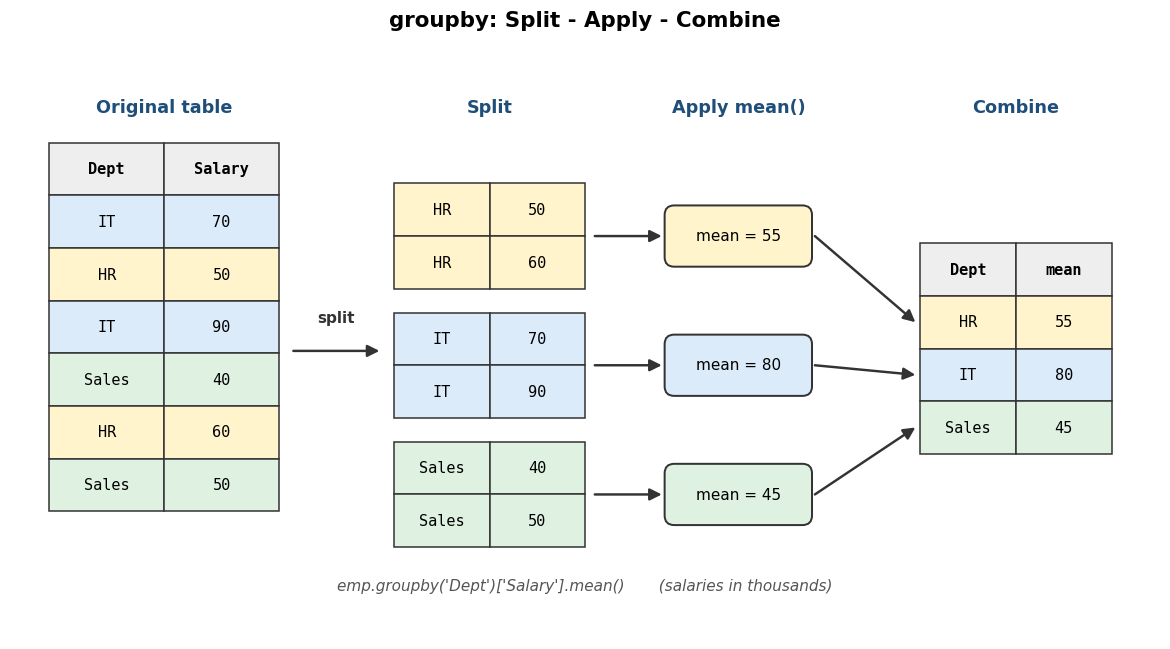

In [ ]:
# Example 1: One statistic and several statistics per group
print(emp.groupby('Dept')['Salary'].mean())
print(emp.groupby('Dept')['Salary'].agg(['count', 'mean', 'max']))
# Expected output:
# Dept
# HR       51500.0
# IT       73250.0
# Sales    48000.0
# Name: Salary, dtype: float64
#        count     mean    max
# Dept
# HR         2  51500.0  65000
# IT         4  73250.0  95000
# Sales      3  48000.0  55000

In [ ]:
# Example 2: Named aggregation - choose the names of the result columns
summary = emp.groupby('Dept').agg(
    staff=('Name', 'count'),
    avg_salary=('Salary', 'mean'),
    max_exp=('Experience', 'max'),
)
print(summary)
# Expected output:
#        staff  avg_salary  max_exp
# Dept
# HR         2     51500.0        8
# IT         4     73250.0       10
# Sales      3     48000.0        6

In [ ]:
# Example 3: Grouping by two columns gives a MultiIndex
by_two = emp.groupby(['Dept', 'City'])['Salary'].sum()
print(by_two)
print('Index levels:', by_two.index.nlevels)
# Expected output:
# Dept   City
# HR     Mumbai     38000
#        Pune       65000
# IT     Delhi      58000
#        Mumbai     95000
#        Pune      140000
# Sales  Delhi      55000
#        Mumbai     41000
#        Pune       48000
# Name: Salary, dtype: int64
# Index levels: 2

In [ ]:
# Example 4: unstack() turns the inner index level into columns
print(by_two.unstack(fill_value=0))
# Expected output:
# City   Delhi  Mumbai    Pune
# Dept
# HR         0   38000   65000
# IT     58000   95000  140000
# Sales  55000   41000   48000

In [ ]:
# Example 5: pivot_table - average experience by department and city
pt = emp.pivot_table(values='Experience', index='Dept', columns='City', aggfunc='mean', fill_value=0)
print(pt)
# Expected output:
# City   Delhi  Mumbai  Pune
# Dept
# HR       0.0     1.0   8.0
# IT       3.0    10.0   5.5
# Sales    6.0     2.0   4.0

In [ ]:
# Example 6: crosstab - how many employees in each Dept and City combination?
print(pd.crosstab(emp['Dept'], emp['City']))
# Expected output:
# City   Delhi  Mumbai  Pune
# Dept
# HR         0       1     1
# IT         1       1     2
# Sales      1       1     1

---
# Part 12: Related Structures - MultiIndex, Categorical and Panel

### MultiIndex
An index with **more than one level**, for example `Dept` and then `City`. It appears when you `groupby` several columns, or `set_index` with a list of columns.
- `s.loc['IT']` selects everything in the outer level `IT`
- `s.loc[('IT', 'Pune')]` selects one exact combination
- `unstack()` moves the inner level into columns (Part 11, Example 4)

### Categorical
A column type for **a few repeating values**. Pandas stores each label once and keeps a small number code for every row, which saves memory. Categories can also have an **order** (`Low < Medium < High`), so they sort and compare correctly. `pd.cut()` and `astype('category')` create categoricals.

### Panel (removed)
Pandas once had a 3-D **Panel** (for example: years x cities x measures). It was removed in **pandas 0.25 (2019)**. Today the same data is stored as a DataFrame with a **MultiIndex**, as in Example 4.

**Diagram: A MultiIndex**

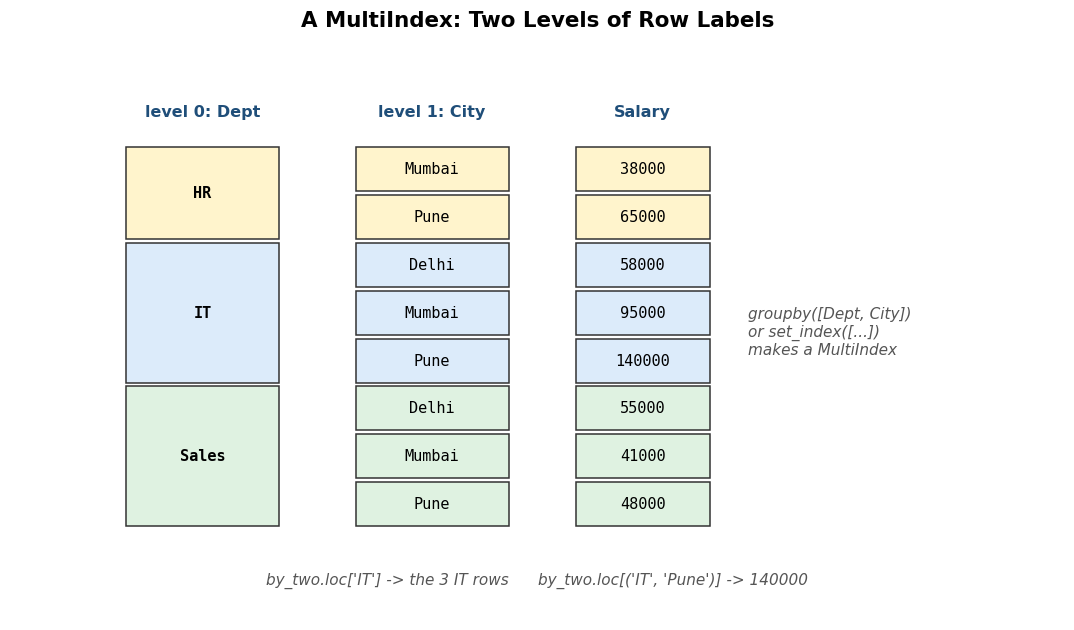

In [ ]:
# Example 1: Selecting from a MultiIndex (by_two from Part 11)
print(by_two.loc['IT'])              # every city for IT
print(by_two.loc[('IT', 'Pune')])    # one exact combination
# Expected output:
# City
# Delhi      58000
# Mumbai     95000
# Pune      140000
# Name: Salary, dtype: int64
# 140000

In [ ]:
# Example 2: A MultiIndex from set_index with two columns
multi = emp.set_index(['Dept', 'Name']).sort_index()
print(multi.loc['HR'])
print(multi.index[:3].tolist())
# Expected output:
#         City  Experience  Salary
# Name
# Meena   Pune           8   65000
# Priya Mumbai           1   38000
# [('HR', 'Meena'), ('HR', 'Priya'), ('IT', 'Asha')]

In [ ]:
# Example 3: An ordered Categorical
seg = pd.Categorical(['Medium', 'Low', 'High', 'Low'], categories=['Low', 'Medium', 'High'], ordered=True)
s = pd.Series(seg)
print(s)
print(s.cat.codes.tolist())          # the small numbers stored for each row
print(s.sort_values().tolist())      # sorts by the category order, not alphabetically
print((s > 'Low').tolist())          # comparisons follow the order too
# Expected output:
# 0    Medium
# 1       Low
# 2      High
# 3       Low
# dtype: category
# Categories (3, object): ['Low' < 'Medium' < 'High']
# [1, 0, 2, 0]
# ['Low', 'Low', 'Medium', 'High']
# [True, False, True, False]

In [ ]:
# Example 4: Panel-style data today - years x cities x measures, as a MultiIndex DataFrame
panel_like = pd.DataFrame({
    'Year': [2024, 2024, 2025, 2025],
    'City': ['Pune', 'Delhi', 'Pune', 'Delhi'],
    'Sales': [120, 150, 135, 160],
    'Profit': [20, 25, 24, 30],
}).set_index(['Year', 'City'])
print(panel_like)
print(panel_like.loc[2025])
# Expected output:
#             Sales  Profit
# Year City
# 2024 Pune     120      20
#      Delhi    150      25
# 2025 Pune     135      24
#      Delhi    160      30
#        Sales  Profit
# City
# Pune     135      24
# Delhi    160      30

---
# Part 13: Combining DataFrames

| Tool | Joins | Typical use |
|---|---|---|
| `pd.concat([a, b])` | stacks tables **on top of each other** (or side by side with `axis=1`) | January sales + February sales |
| `pd.merge(a, b, on='key', how=...)` | matches rows using a **key column**, like SQL JOIN | employees + department details |
| `a.join(b)` | matches rows using the **index** | |

**The `how` argument of merge**

| how | Keeps |
|---|---|
| `'inner'` (default) | only keys found in **both** tables |
| `'left'` | every row of the left table |
| `'right'` | every row of the right table |
| `'outer'` | every key from both tables |

Missing matches are filled with `NaN`. Always check the number of rows after a merge: repeated keys can multiply rows.

**Diagram: Types of merge**

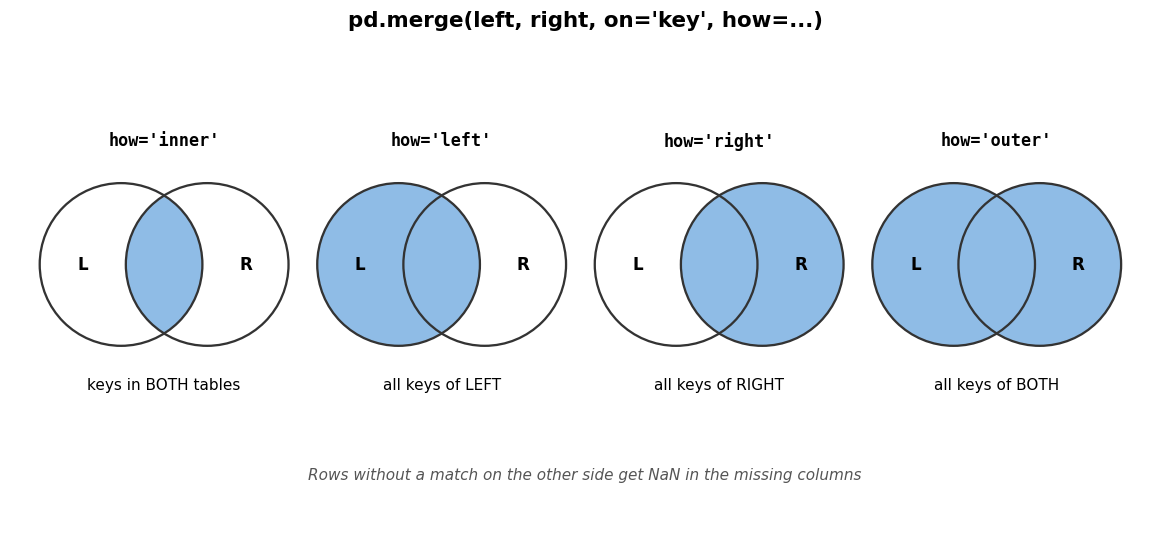

In [ ]:
# Example 1: concat - stacking rows
jan = pd.DataFrame({'Item': ['Pen', 'Book'], 'Qty': [10, 2]})
feb = pd.DataFrame({'Item': ['Bag', 'Pen'], 'Qty': [1, 5]})
print(pd.concat([jan, feb], ignore_index=True))          # new index 0, 1, 2, 3
print(pd.concat([jan, feb], keys=['Jan', 'Feb']))        # keys make a MultiIndex
# Expected output:
#    Item  Qty
# 0   Pen   10
# 1  Book    2
# 2   Bag    1
# 3   Pen    5
#        Item  Qty
# Jan 0   Pen   10
#     1  Book    2
# Feb 0   Bag    1
#     1   Pen    5

In [ ]:
# Example 2: concat with axis=1 - side by side
names = pd.Series(['Asha', 'Ravi'], name='Name')
scores = pd.Series([88, 74], name='Score')
print(pd.concat([names, scores], axis=1))
# Expected output:
#    Name  Score
# 0  Asha     88
# 1  Ravi     74

In [ ]:
# Example 3: merge - add department details to every employee
depts = pd.DataFrame({'Dept': ['IT', 'HR', 'Sales', 'Finance'],
                      'Floor': [3, 1, 2, 4],
                      'Head': ['Mr. Rao', 'Ms. Iyer', 'Mr. Khan', 'Ms. Das']})
merged = pd.merge(emp[['Name', 'Dept']], depts, on='Dept', how='left')
print(merged.head(4))
for how in ['inner', 'left', 'right', 'outer']:
    result = pd.merge(emp[['Name', 'Dept']], depts, on='Dept', how=how)
    print(how, len(result))
no_staff = pd.merge(emp[['Name', 'Dept']], depts, on='Dept', how='right')
print(no_staff.loc[no_staff['Name'].isnull(), 'Dept'].tolist())     # departments with nobody
# Expected output:
#     Name   Dept  Floor      Head
# 0   Asha     IT      3   Mr. Rao
# 1   Ravi  Sales      2  Mr. Khan
# 2  Meena     HR      1  Ms. Iyer
# 3   John     IT      3   Mr. Rao
# inner 9
# left 9
# right 10
# outer 10
# ['Finance']

In [ ]:
# Example 4: join - match rows by their index
salaries = emp.set_index('Name')[['Salary']]
ratings = pd.DataFrame({'Rating': [4.5, 3.8, 4.9]},
                       index=pd.Index(['Asha', 'Kiran', 'Neha'], name='Name'))
print(salaries.join(ratings, how='inner'))
# Expected output:
#        Salary  Rating
# Name
# Asha    72000     4.5
# Kiran   95000     3.8
# Neha    68000     4.9

---
# Part 14: Reshaping Data

The same data can be stored **wide** (one column per subject) or **long** (one row per student and subject). Many tools need the long form; people usually find the wide form easier to read.

| Tool | Does |
|---|---|
| `melt()` | wide to long: columns become rows |
| `pivot()` | long to wide: the values of one column become columns |
| `stack()` | moves the columns into the inner level of the row index (gives a Series) |
| `unstack()` | moves the inner level of the row index into columns |

`pivot` needs each index/column pair to appear only once; if pairs repeat, use `pivot_table` with an `aggfunc` (Part 11).

**Diagram: melt() and pivot()**

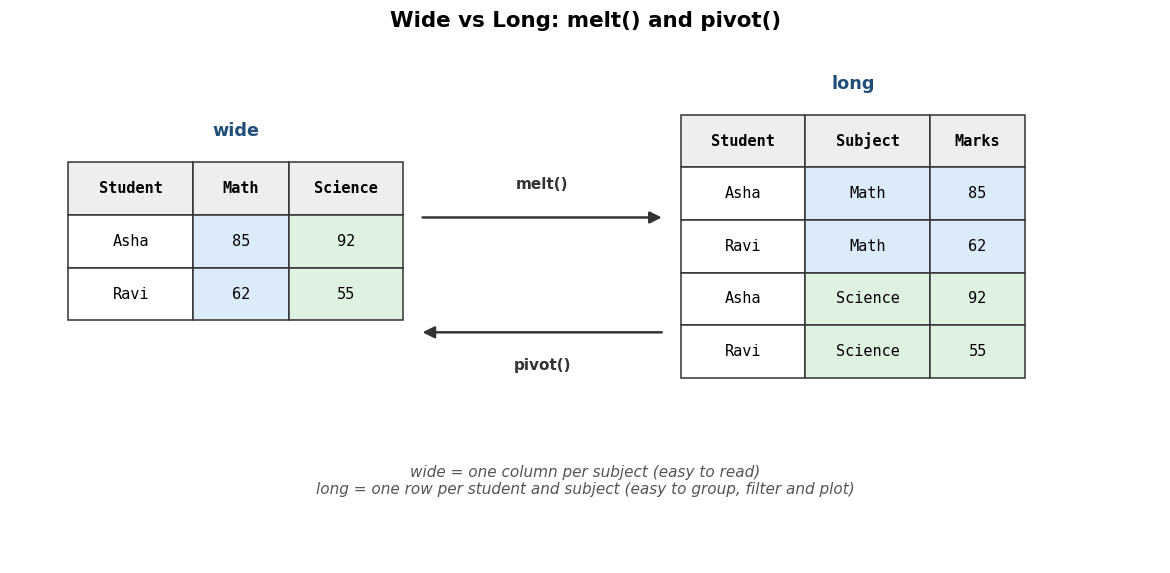

In [ ]:
# Example 1: melt - wide to long
wide = pd.DataFrame({'Student': ['Asha', 'Ravi'],
                     'Math': [85, 62],
                     'Science': [92, 55]})
print(wide)
long = wide.melt(id_vars='Student', var_name='Subject', value_name='Marks')
print(long)
# Expected output:
#   Student  Math  Science
# 0    Asha    85       92
# 1    Ravi    62       55
#   Student  Subject  Marks
# 0    Asha     Math     85
# 1    Ravi     Math     62
# 2    Asha  Science     92
# 3    Ravi  Science     55

In [ ]:
# Example 2: pivot - long back to wide
back = long.pivot(index='Student', columns='Subject', values='Marks')
print(back)
# Expected output:
# Subject  Math  Science
# Student
# Asha       85       92
# Ravi       62       55

In [ ]:
# Example 3: stack and unstack
stacked = back.stack()             # columns move into the row index (pandas 2.1+ may show a harmless FutureWarning)
print(stacked)
print(stacked.unstack().equals(back))     # unstack undoes stack
# Expected output:
# Student  Subject
# Asha     Math       85
#          Science    92
# Ravi     Math       62
#          Science    55
# dtype: int64
# True

---
# Part 15: Statistics

| Method | Gives |
|---|---|
| `mean()`, `median()` | average, middle value |
| `mode()` | the most frequent value(s); it returns a Series, so take `[0]` |
| `std()` | standard deviation (pandas divides by n - 1; NumPy's `std()` divides by n) |
| `quantile(q)` | the value below which a fraction q of the data lies; `0.5` is the median |
| `corr()` | correlation between number columns, from -1 to 1 |
| `min()`, `max()`, `sum()`, `count()` | the usual summaries |

On a DataFrame these work column by column; add `numeric_only=True` to skip text columns.

**Correlation** near **1** means the two columns rise together, near **-1** means one falls as the other rises, and near **0** means no straight-line relationship. Correlation does not prove that one causes the other.

In [ ]:
# Example 1: The main statistics
print(emp['Salary'].mean(), emp['Salary'].median())
print(emp['City'].mode()[0], emp['Experience'].mode()[0])
print(round(emp['Salary'].std(), 2))
print(emp['Salary'].quantile([0.25, 0.5, 0.75]))
print(emp.mean(numeric_only=True))
# Expected output:
# 60000.0 58000.0
# Pune 6
# 17592.61
# 0.25    48000.0
# 0.50    58000.0
# 0.75    68000.0
# Name: Salary, dtype: float64
# Experience        5.0
# Salary        60000.0
# dtype: float64

In [ ]:
# Example 2: Correlation - do salaries rise with experience?
print(emp[['Experience', 'Salary']].corr().round(2))
print(round(emp['Experience'].corr(emp['Salary']), 3))
# Expected output:
#             Experience  Salary
# Experience        1.00    0.88
# Salary            0.88    1.00
# 0.876

In [ ]:
# Example 3: Statistics per group
print(emp.groupby('Dept')['Experience'].median())
# Expected output:
# Dept
# HR       4.5
# IT       5.5
# Sales    4.0
# Name: Experience, dtype: float64

---
# Part 16: The .str Accessor (Text)

`.str` gives a text column all the string methods, applied to every value at once (missing values stay missing).

| Code | Does |
|---|---|
| `s.str.lower()`, `.upper()`, `.title()` | change the case |
| `s.str.strip()` | remove spaces at both ends |
| `s.str.replace(old, new)` | replace text |
| `s.str.contains(text)` | True/False: does the value contain the text? |
| `s.str.startswith(text)` | True/False |
| `s.str.len()` | number of characters |
| `s.str.split(sep)` | split into lists; `expand=True` gives separate columns |
| `s.str[0]` | the first character (or the first item after `split`) |

In [ ]:
# Example 1: Cleaning and exploring names
raw_names = pd.Series(['  asha patil', 'RAVI kumar ', 'Meena Shah', 'john DSouza'])
names = raw_names.str.strip().str.title()
print(names)
print(names.str.split().str[0].tolist())          # first names
print(names.str.len().tolist())
print(names.str.contains('Sh').tolist())
print(names.str.upper().str.replace(' ', '_').tolist())
# Expected output:
# 0     Asha Patil
# 1     Ravi Kumar
# 2     Meena Shah
# 3    John Dsouza
# dtype: object
# ['Asha', 'Ravi', 'Meena', 'John']
# [10, 10, 10, 11]
# [False, False, True, False]
# ['ASHA_PATIL', 'RAVI_KUMAR', 'MEENA_SHAH', 'JOHN_DSOUZA']

In [ ]:
# Example 2: Splitting codes into columns
codes = pd.Series(['IT-101', 'HR-205', 'SALES-330'])
print(codes.str.split('-', expand=True))
print(codes.str.startswith('IT').tolist())
print(codes.str.lower().tolist())
# Expected output:
#        0    1
# 0     IT  101
# 1     HR  205
# 2  SALES  330
# [True, False, False]
# ['it-101', 'hr-205', 'sales-330']

In [ ]:
# Example 3: Turning price text into numbers
price_text = pd.Series(['Rs. 1,200', 'Rs. 450', 'Rs. 15,000'])
price = price_text.str.replace('Rs. ', '').str.replace(',', '').astype(int)
print(price.tolist(), price.sum())
# Expected output: [1200, 450, 15000] 16650

---
# Part 17: The .dt Accessor (Dates)

First convert text to real dates with `pd.to_datetime()`. Then `.dt` gives the parts of each date:

| Code | Gives |
|---|---|
| `s.dt.year`, `.month`, `.day` | numbers |
| `s.dt.day_name()`, `.month_name()` | `'Monday'`, `'January'` |
| `s.dt.dayofweek` | 0 = Monday ... 6 = Sunday |
| `s.dt.strftime('%Y-%m')` | formatted text, such as `'2026-01'` |
| `date2 - date1` | a **timedelta**; `.dt.days` gives the number of days |

Dates can be compared and filtered: `df[df['BillDate'] >= '2026-02-01']`. For dates written day-first (`05-01-2026`), give the format: `pd.to_datetime(s, format='%d-%m-%Y')`.

In [ ]:
# Example 1: Getting parts of a date
bills = pd.DataFrame({'BillDate': ['2026-01-15', '2026-02-03', '2026-02-28', '2026-03-10'],
                      'Amount': [1200, 450, 3000, 800]})
bills['BillDate'] = pd.to_datetime(bills['BillDate'])
bills['Year'] = bills['BillDate'].dt.year
bills['Month'] = bills['BillDate'].dt.month
bills['Day'] = bills['BillDate'].dt.day_name()
print(bills)
# Expected output:
#     BillDate  Amount  Year  Month       Day
# 0 2026-01-15    1200  2026      1  Thursday
# 1 2026-02-03     450  2026      2   Tuesday
# 2 2026-02-28    3000  2026      2  Saturday
# 3 2026-03-10     800  2026      3   Tuesday

In [ ]:
# Example 2: Date arithmetic, filtering and grouping by month
today = pd.Timestamp('2026-03-31')
bills['DaysAgo'] = (today - bills['BillDate']).dt.days
print(bills[['BillDate', 'DaysAgo']])
print(bills[bills['BillDate'] >= '2026-02-01']['Amount'].sum())
print(bills.groupby('Month')['Amount'].sum())
print(bills['BillDate'].dt.month_name().tolist())
# Expected output:
#     BillDate  DaysAgo
# 0 2026-01-15       75
# 1 2026-02-03       56
# 2 2026-02-28       31
# 3 2026-03-10       21
# 4250
# Month
# 1    1200
# 2    3450
# 3     800
# Name: Amount, dtype: int64
# ['January', 'February', 'February', 'March']

In [ ]:
# Example 3: Day-first dates (common in India) and formatting dates as text
indian_dates = pd.Series(['05-01-2026', '20-02-2026'])
parsed = pd.to_datetime(indian_dates, format='%d-%m-%Y')
print(parsed.dt.strftime('%d %b %Y').tolist())
print(parsed.dt.dayofweek.tolist())          # 0 = Monday
# Expected output:
# ['05 Jan 2026', '20 Feb 2026']
# [0, 4]

---
# Part 18: Plotting

Pandas draws charts directly from a Series or DataFrame using **Matplotlib**.

| Code | Chart | Good for |
|---|---|---|
| `s.plot()` or `kind='line'` | line chart | trends over time |
| `kind='bar'` / `'barh'` | bar chart | comparing categories |
| `s.hist(bins=5)` or `kind='hist'` | histogram | how numbers are spread |
| `df.plot(kind='scatter', x=..., y=...)` | scatter plot | the relationship between two columns |
| `kind='pie'` | pie chart | shares of a whole |
| `kind='box'` | box plot | spread and outliers |

Add a title with `title='...'`, labels with `plt.xlabel()` / `plt.ylabel()`, then `plt.show()` to display the chart.

In [ ]:
# Example 1: Bar chart - compare categories
import matplotlib.pyplot as plt

dept_avg = emp.groupby('Dept')['Salary'].mean()
dept_avg.plot(kind='bar', title='Average Salary by Department', color='steelblue', rot=0)
plt.ylabel('Salary (Rs.)')
plt.show()
# Expected output: a bar chart with 3 bars - HR 51500, IT 73250, Sales 48000

In [ ]:
# Example 2: Line chart - a trend over time
monthly = pd.Series([120, 135, 150, 145, 170, 190], index=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])
monthly.plot(kind='line', marker='o', title='Monthly Sales (units)')
plt.show()
# Expected output: a rising line with one dot per month (a small dip in April)

In [ ]:
# Example 3: Histogram - how the salaries are spread
emp['Salary'].hist(bins=5)
plt.title('How Salaries Are Spread')
plt.xlabel('Salary (Rs.)')
plt.ylabel('Number of employees')
plt.show()
# Expected output: 5 bars; most employees fall between about 38000 and 70000, one at 95000

In [ ]:
# Example 4: Scatter plot - the relationship between two columns
emp.plot(kind='scatter', x='Experience', y='Salary', title='Experience vs Salary')
plt.show()
# Expected output: 9 dots that rise from left to right (correlation 0.88, Part 15)

In [ ]:
# Example 5: Pie chart - shares of a whole
emp['Dept'].value_counts().plot(kind='pie', autopct='%1.0f%%', title='Staff by Department')
plt.ylabel('')
plt.show()
# Expected output: a pie with IT 44%, Sales 33%, HR 22%

---
# Part 19: Quick Recap

| Task | Code |
|---|---|
| Import | `import pandas as pd` |
| Create | `pd.Series(list)`, `pd.DataFrame(dict)` |
| Read / write | `pd.read_csv('f.csv')`, `df.to_csv('f.csv', index=False)` |
| Look | `df.head()`, `df.info()`, `df.describe()`, `df.shape` |
| One column / several | `df['A']`, `df[['A', 'B']]` |
| By label / by position | `df.loc[label, 'A']`, `df.iloc[0, 1]` |
| Filter | `df[(df['A'] > 5) & (df['B'] == 'x')]`, `df.query('A > 5')` |
| Missing values | `df.isnull().sum()`, `fillna()`, `dropna()` |
| Duplicates | `df.duplicated()`, `drop_duplicates()` |
| Types | `astype()`, `pd.to_numeric()`, `pd.to_datetime()` |
| New columns | `df['C'] = df['A'] * 2`, `apply()`, `map()`, `pd.cut()` |
| Sort / count | `sort_values()`, `value_counts()`, `unique()`, `nunique()` |
| Group | `df.groupby('A')['B'].mean()`, `agg()`, `pivot_table()`, `pd.crosstab()` |
| Combine | `pd.concat()`, `pd.merge(a, b, on='key', how='left')`, `join()` |
| Reshape | `melt()`, `pivot()`, `stack()`, `unstack()` |
| Text / dates | `.str.strip()`, `.str.title()`, `.dt.month`, `.dt.day_name()` |
| Plot | `s.plot(kind='bar')`, `s.hist()` |

### Common beginner mistakes
1. **`df['A']` vs `df[['A']]`**: single brackets give a Series, double brackets give a DataFrame.
2. **The dot operator with unusual names**: `df.Monthly Salary` or `df.count` do not give the column; use `df['...']`.
3. **Forgetting that `loc` includes the end label**, while `iloc` excludes the end position.
4. **Using `and` / `or`** instead of `&` / `|`, or forgetting the brackets around each condition.
5. **Chained assignment** such as `df[df['A'] > 5]['B'] = 0`: use `df.loc[df['A'] > 5, 'B'] = 0`.
6. **Not saving the result** of `dropna()`, `fillna()`, `sort_values()` or `rename()`: write `df = df.dropna()`.
7. **Doing maths with numbers stored as text**: convert with `astype()` or `pd.to_numeric()` first.
8. **Using `.dt` on text dates**: convert with `pd.to_datetime()` first.
9. **Forgetting `index=False` in `to_csv()`**: the file gets an extra *Unnamed: 0* column when read back.
10. **Merging on keys that repeat**: rows multiply; check `len()` before and after a merge.
11. **Forgetting that `groupby` puts the groups in the index**: use `reset_index()` to get a normal column back.
12. **Comparing with `== None` or `== np.nan`**: find missing values with `isnull()`.

---
# Part 20: Practice Exercises

Run the setup cell first. Then solve each exercise in the empty code cell below it. Exercises 2 to 12 use the `students` table, and some build on earlier ones (Exercise 5 needs the filled Math column from Exercise 3, for example), so solve them in order.

In [ ]:
# Setup for the exercises
students = pd.DataFrame({
    'Name': ['Asha', 'Ravi', 'Meena', 'John', 'Sara', 'Kiran'],
    'Class': ['10A', '10B', '10A', '10B', '10A', '10B'],
    'Math': [85, 62, 91, 45, 76, None],
    'Science': [92, 55, 88, 38, 81, 72],
    'City': ['Pune', 'mumbai', 'Pune', 'Delhi', 'delhi', ' pune'],
})
print(students)
# Expected output:
#     Name Class  Math  Science    City
# 0   Asha   10A  85.0       92    Pune
# 1   Ravi   10B  62.0       55  mumbai
# 2  Meena   10A  91.0       88    Pune
# 3   John   10B  45.0       38   Delhi
# 4   Sara   10A  76.0       81   delhi
# 5  Kiran   10B   NaN       72    pune

### Exercise 1: Series

Create a Series of fruit prices: Apple 120, Banana 40, Mango 150, Grapes 90. Print the name of the most expensive fruit, then the fruits that cost more than 100.

**Expected output:**
```
Mango
Apple    120
Mango    150
dtype: int64
```

In [ ]:
# Write your code here


### Exercise 2: Inspecting

Print the shape, the list of column names and the data types of `students`.

**Expected output:**
```
(6, 5)
['Name', 'Class', 'Math', 'Science', 'City']
Name        object
Class       object
Math       float64
Science      int64
City        object
dtype: object
```

In [ ]:
# Write your code here


### Exercise 3: Missing Values

Print how many values are missing in the whole table. Then fill the missing Math mark with the average Math mark, and print Kiran's Math mark.

**Expected output:**
```
Missing values: 1
71.8
```

In [ ]:
# Write your code here


### Exercise 4: Cleaning Text

Clean the City column (remove the extra spaces, use Title Case), then count the students in each city.

**Expected output:**
```
City
Pune      3
Delhi     2
Mumbai    1
Name: count, dtype: int64
```

In [ ]:
# Write your code here


### Exercise 5: New Column and Sorting

Add a `Total` column (Math + Science). Print the names of the two students with the highest totals.

**Expected output:**
```
['Meena', 'Asha']
```

In [ ]:
# Write your code here


### Exercise 6: loc and iloc

Using `loc`, print the Science marks of the rows labelled 1 to 3 as a list. Using `iloc`, print the first 2 rows and the first 2 columns.

**Expected output:**
```
[55, 88, 38]
   Name Class
0  Asha   10A
1  Ravi   10B
```

In [ ]:
# Write your code here


### Exercise 7: Filtering

Print the names of the students in class 10A who scored 80 or more in Science.

**Expected output:**
```
['Asha', 'Meena', 'Sara']
```

In [ ]:
# Write your code here


### Exercise 8: groupby

Print the average Science mark of each class.

**Expected output:**
```
Class
10A    87.0
10B    55.0
Name: Science, dtype: float64
```

In [ ]:
# Write your code here


### Exercise 9: pd.cut

Add a `Level` column from the Science marks: 0-50 `'Needs help'`, 51-75 `'Average'`, 76-100 `'Good'` (bins `[0, 50, 75, 100]`). Count each level, keeping the level order.

**Expected output:**
```
Level
Needs help    1
Average       2
Good          3
Name: count, dtype: int64
```

In [ ]:
# Write your code here


### Exercise 10: merge

Create `teachers = pd.DataFrame({'Class': ['10A', '10B'], 'Teacher': ['Mr. Rao', 'Ms. Iyer']})`. Merge it with `students` and print the Name and Teacher columns of the first 2 rows.

**Expected output:**
```
   Name   Teacher
0  Asha   Mr. Rao
1  Ravi  Ms. Iyer
```

In [ ]:
# Write your code here


### Exercise 11: melt

Melt the Name, Math and Science columns into a long table with the columns `Name`, `Subject` and `Marks`. Print its shape and its first 2 rows.

**Expected output:**
```
(12, 3)
   Name Subject  Marks
0  Asha    Math   85.0
1  Ravi    Math   62.0
```

In [ ]:
# Write your code here


### Exercise 12: Class Report (Challenge)

Print the average Math and Science marks of each class, rounded to 1 decimal place, in one table.

**Expected output:**
```
       Math  Science
Class
10A    84.0     87.0
10B    59.6     55.0
```

In [ ]:
# Write your code here


---
# Part 21: Final Project - Online Store Sales Analysis

An online store sends you its orders for January to March 2026 as a CSV file. The file is messy: it has a duplicate row, missing values, city names typed in different ways, and prices stored as text such as `Rs. 55000`.

**Our program will:**
1. Load the file safely
2. Inspect it to find the problems
3. Clean it
4. Enrich it: add product categories (merge), revenue, month, weekday and order size
5. Analyse it: totals, categories, cities, customers
6. Analyse it over time: months, a pivot table, a crosstab, a reshape
7. Visualise the results
8. Save a cleaned CSV file and a text report
9. Look up any city interactively

**Where each concept is used**

| Topic | Used in |
|---|---|
| Input / Output | `read_csv`, `to_csv`, the report file |
| Inspecting | `shape`, `dtypes`, `isnull`, `duplicated`, `unique` |
| Cleaning | `drop_duplicates`, `.str.strip()`, `.str.title()`, `fillna`, `astype`, `.str.replace()` |
| Transforming | new columns, `pd.cut` (Categorical), `value_counts`, `nlargest` |
| Dates | `pd.to_datetime`, `.dt.strftime()`, `.dt.day_name()` |
| Combining | `merge` with a product table |
| Grouping | `groupby` + `agg`, `pivot_table`, `crosstab` |
| Reshaping | `melt` |
| Plotting | bar and line charts |
| Earlier labs | functions, exceptions, text files, loops, `input()` |

**Run every step in order.**

**Diagram: How the sales analysis works**

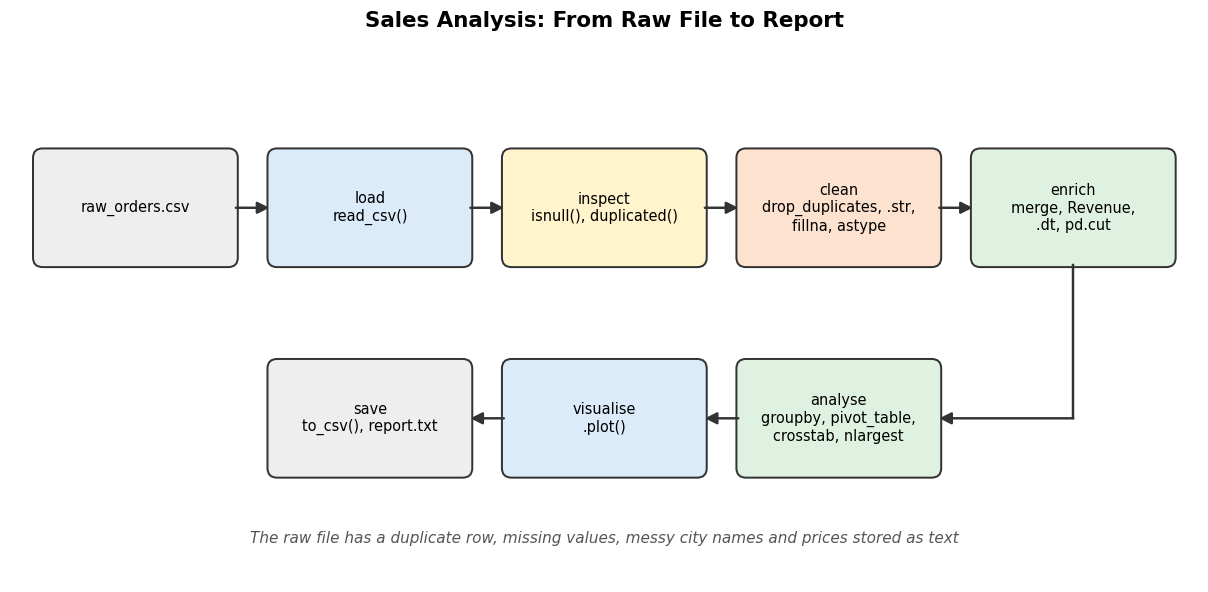

### Step 1: Create the Raw Orders File

In [ ]:
# Step 1: The raw orders file, as it might arrive from the shop's website
import pandas as pd
import matplotlib.pyplot as plt

raw_lines = [
    'OrderID,Date,Customer,City,Product,Qty,Price',
    '1001,2026-01-05,Asha,Pune,Laptop,1,Rs. 55000',
    '1002,2026-01-12,Ravi, mumbai ,Phone,2,Rs. 18000',
    '1003,2026-01-20,Meena,PUNE,Chair,4,Rs. 3500',
    '1004,2026-02-02,John,Delhi,Notebook,,Rs. 60',
    '1005,2026-02-14,Sara,delhi,Headphones,2,Rs. 2500',
    '1005,2026-02-14,Sara,delhi,Headphones,2,Rs. 2500',
    '1006,2026-02-20,Kiran,Mumbai,Desk,1,Rs. 12000',
    '1007,2026-03-03,,Pune,Pen,10,Rs. 20',
    '1008,2026-03-08,Priya,Mumbai,Laptop,1,Rs. 62000',
    '1009,2026-03-15,Arjun,Delhi,Chair,2,Rs. 3500',
    '1010,2026-03-22,Neha,Pune,Phone,1,Rs. 21000',
    '1011,2026-03-28,Asha,Pune,Notebook,5,Rs. 60',
]
with open('raw_orders.csv', 'w', encoding='utf-8') as f:
    for line in raw_lines:
        f.write(line + '\n')
print('raw_orders.csv created with', len(raw_lines) - 1, 'order lines')
# Expected output: raw_orders.csv created with 12 order lines

### Step 2: Load and Inspect

`load_orders()` returns `None` instead of crashing when the file is missing (Exception Handling lab). Then we look for problems before changing anything.

In [ ]:
# Step 2: Load the file safely and look for problems
def load_orders(filename):
    """Read the orders file; return None if it does not exist."""
    try:
        return pd.read_csv(filename)
    except FileNotFoundError:
        print(f'{filename} was not found')
        return None

load_orders('orders_2025.csv')          # a file that does not exist
raw = load_orders('raw_orders.csv')
print(raw.shape)
print(raw.dtypes[['Qty', 'Price']])     # Qty is float (it has a gap), Price is text
print(raw.isnull().sum())
print('Duplicate rows:', raw.duplicated().sum())
print(raw['City'].unique())
# Expected output:
# orders_2025.csv was not found
# (12, 7)
# Qty      float64
# Price     object
# dtype: object
# OrderID     0
# Date        0
# Customer    1
# City        0
# Product     0
# Qty         1
# Price       0
# dtype: int64
# Duplicate rows: 1
# ['Pune' ' mumbai ' 'PUNE' 'Delhi' 'delhi' 'Mumbai']

### Step 3: Clean

One function fixes every problem found in Step 2 and returns a **new** table; the raw data stays untouched.

In [ ]:
# Step 3: Fix duplicates, text, missing values and types
def clean_orders(raw):
    """Return a cleaned copy of the raw orders."""
    df = raw.drop_duplicates().copy()
    df['City'] = df['City'].str.strip().str.title()           # ' mumbai ' -> 'Mumbai'
    df['Customer'] = df['Customer'].fillna('Guest')
    df['Qty'] = df['Qty'].fillna(1).astype(int)              # a missing quantity counts as 1
    df['Price'] = df['Price'].str.replace('Rs. ', '').astype(int)
    df['Date'] = pd.to_datetime(df['Date'])
    return df.reset_index(drop=True)

orders = clean_orders(raw)
print(orders[['Date', 'Customer', 'City', 'Qty', 'Price']].head(4))
print('Rows:', len(orders), '| missing values:', orders.isnull().sum().sum(),
      '| duplicates:', orders.duplicated().sum())
print(orders['City'].unique())
# Expected output:
#         Date Customer    City  Qty  Price
# 0 2026-01-05     Asha    Pune    1  55000
# 1 2026-01-12     Ravi  Mumbai    2  18000
# 2 2026-01-20    Meena    Pune    4   3500
# 3 2026-02-02     John   Delhi    1     60
# Rows: 11 | missing values: 0 | duplicates: 0
# ['Pune' 'Mumbai' 'Delhi']

### Step 4: Enrich

The product categories live in a separate table, so we **merge** them in. Then we add the revenue, the month, the weekday and an order-size **Categorical** made with `pd.cut`. If a product has no category, the function raises an error instead of silently producing wrong totals.

In [ ]:
# Step 4: Add categories and new columns
products = pd.DataFrame({
    'Product': ['Laptop', 'Phone', 'Headphones', 'Chair', 'Desk', 'Notebook', 'Pen'],
    'Category': ['Electronics', 'Electronics', 'Electronics', 'Furniture', 'Furniture',
                 'Stationery', 'Stationery'],
})

def enrich(orders, products):
    """Add Category, Revenue, Month, Day and Size columns."""
    df = pd.merge(orders, products, on='Product', how='left')
    if df['Category'].isnull().any():
        raise ValueError('some products have no category')
    df['Revenue'] = df['Qty'] * df['Price']
    df['Month'] = df['Date'].dt.strftime('%Y-%m')
    df['Day'] = df['Date'].dt.day_name()
    df['Size'] = pd.cut(df['Revenue'], bins=[0, 1000, 20000, 100000], labels=['Small', 'Medium', 'Large'])
    return df

orders = enrich(orders, products)
print(orders[['Product', 'Category', 'Revenue', 'Size']].head(4))
print(orders['Size'].value_counts(sort=False))
# Expected output:
#     Product     Category  Revenue    Size
# 0    Laptop  Electronics    55000   Large
# 1     Phone  Electronics    36000   Large
# 2     Chair    Furniture    14000  Medium
# 3  Notebook   Stationery       60   Small
# Size
# Small     3
# Medium    4
# Large     4
# Name: count, dtype: int64

### Step 5: Analyse - Totals, Categories, Cities and Customers

In [ ]:
# Step 5: The big picture
revenue = orders['Revenue']
print(f'Orders: {len(orders)} | total revenue: Rs. {revenue.sum():,} | average order: Rs. {revenue.mean():,.0f}')
print()
by_category = orders.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
print(by_category)
print()
city_summary = (orders.groupby('City')
                .agg(orders=('OrderID', 'count'), revenue=('Revenue', 'sum'))
                .sort_values('revenue', ascending=False))
print(city_summary)
print()
print(orders.groupby('Customer')['Revenue'].sum().nlargest(3))      # top 3 customers
# Expected output:
# Orders: 11 | total revenue: Rs. 212,560 | average order: Rs. 19,324
#
# Category
# Electronics    179000
# Furniture       33000
# Stationery        560
# Name: Revenue, dtype: int64
#
#         orders  revenue
# City
# Mumbai       3   110000
# Pune         5    90500
# Delhi        3    12060
#
# Customer
# Priya    62000
# Asha     55300
# Ravi     36000
# Name: Revenue, dtype: int64

### Step 6: Analyse - Months, Pivot Table, Crosstab and Reshape

In [ ]:
# Step 6: Over time and across two dimensions
monthly = orders.groupby('Month')['Revenue'].sum()
print(monthly)
print()
monthly_by_category = orders.pivot_table(values='Revenue', index='Month', columns='Category',
                                         aggfunc='sum', fill_value=0)
print(monthly_by_category)
print()
print(pd.crosstab(orders['City'], orders['Size']))     # how many orders of each size per city
print()
long = monthly_by_category.reset_index().melt(id_vars='Month', value_name='Revenue')
print(long.shape, long.columns.tolist())
print('Median order:', revenue.median())
print('Biggest order:', revenue.max(), 'by', orders.loc[revenue.idxmax(), 'Customer'])
# Expected output:
# Month
# 2026-01    105000
# 2026-02     17060
# 2026-03     90500
# Name: Revenue, dtype: int64
#
# Category  Electronics  Furniture  Stationery
# Month
# 2026-01         91000      14000           0
# 2026-02          5000      12000          60
# 2026-03         83000       7000         500
#
# Size    Small  Medium  Large
# City
# Delhi       1       2      0
# Mumbai      0       1      2
# Pune        2       1      2
#
# (9, 3) ['Month', 'Category', 'Revenue']
# Median order: 12000.0
# Biggest order: 62000 by Priya

### Step 7: Visualise

In [ ]:
# Step 7: Two charts
by_category.plot(kind='bar', title='Revenue by Category', color='steelblue', rot=0)
plt.ylabel('Revenue (Rs.)')
plt.show()

monthly.plot(kind='line', marker='o', title='Revenue by Month')
plt.ylabel('Revenue (Rs.)')
plt.show()
# Expected output:
# a bar chart where Electronics (179000) is far taller than Furniture and Stationery,
# and a line that drops sharply in February and recovers in March

### Step 8: Save the Clean Data and a Report

In [ ]:
# Step 8: A cleaned CSV for others, and a short text report for the manager
def write_report(orders, filename='sales_report.txt'):
    """Write the key results to a text file and return its name."""
    rev = orders['Revenue']
    by_cat = orders.groupby('Category')['Revenue'].sum()
    by_city = orders.groupby('City')['Revenue'].sum()
    by_month = orders.groupby('Month')['Revenue'].sum()
    by_customer = orders.groupby('Customer')['Revenue'].sum()
    lines = [
        'SALES REPORT',
        '=' * 36,
        f'Orders        : {len(orders)}',
        f'Total revenue : Rs. {rev.sum():,}',
        f'Average order : Rs. {rev.mean():,.0f}',
        f'Best category : {by_cat.idxmax()} (Rs. {by_cat.max():,})',
        f'Best city     : {by_city.idxmax()} (Rs. {by_city.max():,})',
        f'Best month    : {by_month.idxmax()} (Rs. {by_month.max():,})',
        f'Top customer  : {by_customer.idxmax()} (Rs. {by_customer.max():,})',
    ]
    with open(filename, 'w', encoding='utf-8') as f:
        f.write('\n'.join(lines) + '\n')
    return filename

orders.to_csv('clean_orders.csv', index=False)
print(pd.read_csv('clean_orders.csv').shape)
with open(write_report(orders), 'r', encoding='utf-8') as f:
    print(f.read(), end='')
# Expected output:
# (11, 12)
# SALES REPORT
# ====================================
# Orders        : 11
# Total revenue : Rs. 212,560
# Average order : Rs. 19,324
# Best category : Electronics (Rs. 179,000)
# Best city     : Mumbai (Rs. 110,000)
# Best month    : 2026-01 (Rs. 105,000)
# Top customer  : Priya (Rs. 62,000)

### Step 9: Interactive City Lookup

Type a city name in any case. Unknown cities get a helpful message; type `exit` to stop.

In [ ]:
# Step 9: Look up the orders of any city (uses input)
def city_lookup(orders):
    """Show the orders of a city typed by the user, until 'exit'."""
    cities = orders['City'].unique()
    choices = ', '.join(cities)
    while True:
        city = input('City to look up (or exit): ').strip().title()
        if city == 'Exit':
            print('Goodbye!')
            break
        if city not in cities:
            print(f'  No orders from {city}. Try: {choices}')
            continue
        part = orders[orders['City'] == city]
        total = part['Revenue'].sum()
        print(f'  {len(part)} orders, revenue Rs. {total:,}')
        print(part[['Date', 'Product', 'Revenue']].to_string(index=False))

city_lookup(orders)
# Example run:
# City to look up (or exit): chennai
#   No orders from Chennai. Try: Pune, Mumbai, Delhi
# City to look up (or exit): delhi
#   3 orders, revenue Rs. 12,060
#       Date    Product  Revenue
# 2026-02-02   Notebook       60
# 2026-02-14 Headphones     5000
# 2026-03-15      Chair     7000
# City to look up (or exit): exit
# Goodbye!

### Make It Your Own

1. Find the best weekday: total revenue by the `Day` column
2. Give a 5% discount on Electronics orders above Rs. 30,000 using `loc`, and compare the totals
3. Load the product table from a CSV file, and test what happens when a product is missing from it
4. Save `monthly_by_category` to an Excel file with `to_excel()`
5. Add a `Profit` column using a profit margin per category (merge a second small table)

---
### Well done!

You have completed the Pandas lab. You can now load real data, inspect it, clean it, reshape it, summarise it and report on it. These are the everyday skills of data analysis.